# Projeto de Aprendizagem de Máquina — Custos Médicos

**Faculdade de Tecnologia de Indaiatuba — Desenvolvimento de Software Multiplataforma**  
**Autoras:** Barbara Brandino, Clara Vecchio e Jacqueline Leite da Silva

Comparação de **Regressão Linear Múltipla**, **Random Forest Regressor** e **Support Vector Regressor (SVR)** para prever o custo médico individual (`charges`).

> **Como executar:** rode as células em ordem (*Ambiente de execução → Executar tudo*). As métricas e conclusões devem ser baseadas nos resultados desta execução. O relatório final deve ser exportado em PDF, conforme as orientações da disciplina.


## 1. Resumo

Este projeto utiliza técnicas de aprendizagem de máquina supervisionada para estimar os custos médicos individuais (`charges`) a partir de características demográficas e de saúde presentes na base Medical Cost Personal Dataset. São comparados três modelos de regressão: Regressão Linear Múltipla, Random Forest Regressor e Support Vector Regressor (SVR). O desempenho é avaliado por meio de R², MAE, MAPE e RMSE, com separação entre treino e teste e validação cruzada para apoiar a comparação. Os resultados finais e a escolha do modelo devem ser preenchidos a partir das métricas produzidas ao executar o notebook.

## 2. Introdução e contextualização

Prever custos médicos pode apoiar análises de risco, planejamento financeiro e compreensão dos fatores associados a maiores despesas. A base utilizada contém informações como idade (`age`), sexo (`sex`), índice de massa corporal (`bmi`), número de filhos (`children`), condição de fumante (`smoker`) e região (`region`). A variável-alvo é `charges`, que representa o custo médico individual. O objetivo é identificar quais dos modelos testados apresentam melhor capacidade de previsão em dados não utilizados no treinamento. As associações encontradas não devem ser interpretadas automaticamente como relações de causa e efeito.

## 3. Objetivos do projeto

- Explorar a distribuição da variável-alvo e as relações entre as variáveis disponíveis.
- Preparar os dados, codificando variáveis categóricas e padronizando as variáveis numéricas.
- Treinar e comparar Regressão Linear Múltipla, Random Forest Regressor e SVR.
- Utilizar validação cruzada e busca de hiperparâmetros para avaliar e ajustar os modelos.
- Comparar R², MAE, MAPE e RMSE, além de examinar resíduos e possíveis sinais de overfitting.
- Recomendar um modelo considerando desempenho preditivo, generalização e interpretabilidade.

## Preparação do ambiente

As próximas células importam as bibliotecas e carregam a base de dados. As seções técnicas seguintes documentam a análise exploratória, o pré-processamento, a modelagem e a avaliação.

## 4. Importação das bibliotecas

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 5. Carregamento do dataset

O notebook procura primeiro `insurance.csv` e depois `MedicalCostPersonal_Insurance-DS.csv` na pasta de trabalho. No Google Colab, se não encontrar nenhum deles, permite enviar o CSV. Fora do Colab, utiliza uma cópia pública como alternativa. Depois do carregamento, verifica se todas as colunas esperadas existem.

In [2]:
import os

URL_BACKUP = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
ARQUIVOS_LOCAIS = ["insurance.csv", "MedicalCostPersonal_Insurance-DS.csv"]

arquivo_encontrado = next((nome for nome in ARQUIVOS_LOCAIS if os.path.exists(nome)), None)

if arquivo_encontrado:
    df = pd.read_csv(arquivo_encontrado)
    print(f"Arquivo local carregado: {arquivo_encontrado}")
else:
    try:
        from google.colab import files
        print("Envie o arquivo CSV da base Medical Cost Personal Dataset.")
        up = files.upload()
        if not up:
            raise FileNotFoundError("Nenhum arquivo foi enviado.")
        arquivo_enviado = next(iter(up))
        df = pd.read_csv(arquivo_enviado)
        print(f"Arquivo enviado carregado: {arquivo_enviado}")
    except ImportError:
        # Fora do Google Colab, tenta obter a cópia pública se não houver CSV local.
        df = pd.read_csv(URL_BACKUP)
        print("Cópia pública do dataset carregada.")

colunas_esperadas = {"age", "sex", "bmi", "children", "smoker", "region", "charges"}
colunas_ausentes = colunas_esperadas - set(df.columns)
if colunas_ausentes:
    raise ValueError(
        "A base carregada não tem as colunas esperadas. "
        f"Colunas ausentes: {sorted(colunas_ausentes)}. Confira se selecionou o CSV correto."
    )

df.head()

Arquivo local carregado: MedicalCostPersonal_Insurance-DS.csv


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 6. Conhecendo os dados

In [3]:
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")
print("\nColunas:", list(df.columns))
print("\nTipos de dados:")
print(df.dtypes)

Linhas: 1338 | Colunas: 7

Colunas: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

Tipos de dados:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


In [4]:
display(df.describe().T)
print("Média de charges:", round(df["charges"].mean(), 2))
print("Mediana de charges:", round(df["charges"].median(), 2))
print("Assimetria (skew) de charges:", round(df["charges"].skew(), 3))

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


Média de charges: 13270.42
Mediana de charges: 9382.03
Assimetria (skew) de charges: 1.516


## 7. Qualidade dos dados
Completude, unicidade, validade e padronização das categorias. **A duplicata é removida aqui**, antes de qualquer divisão treino/teste.

In [5]:
print("Valores ausentes por coluna:")
print(df.isnull().sum())

print("\nLinhas duplicadas:", df.duplicated().sum())
display(df[df.duplicated(keep=False)])

print("\nCategorias:")
for col in ["sex", "smoker", "region"]:
    print(f"  {col}: {sorted(df[col].unique())}")

print("\nFaixas de valores (validade):")
print(f"  age: {df['age'].min()} a {df['age'].max()}")
print(f"  bmi: {df['bmi'].min()} a {df['bmi'].max()}")
print(f"  children: {df['children'].min()} a {df['children'].max()}")
print(f"  charges: {df['charges'].min():.2f} a {df['charges'].max():.2f}")

Valores ausentes por coluna:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Linhas duplicadas: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631



Categorias:
  sex: ['female', 'male']
  smoker: ['no', 'yes']
  region: ['northeast', 'northwest', 'southeast', 'southwest']

Faixas de valores (validade):
  age: 18 a 64
  bmi: 15.96 a 53.13
  children: 0 a 5
  charges: 1121.87 a 63770.43


In [6]:
n_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Registros antes: {n_antes} | depois de remover duplicatas: {len(df)}")

Registros antes: 1338 | depois de remover duplicatas: 1337


## 8. Análise Exploratória de Dados (EDA)

### 8.1 Distribuições

ValueError: Invalid RGBA argument: None

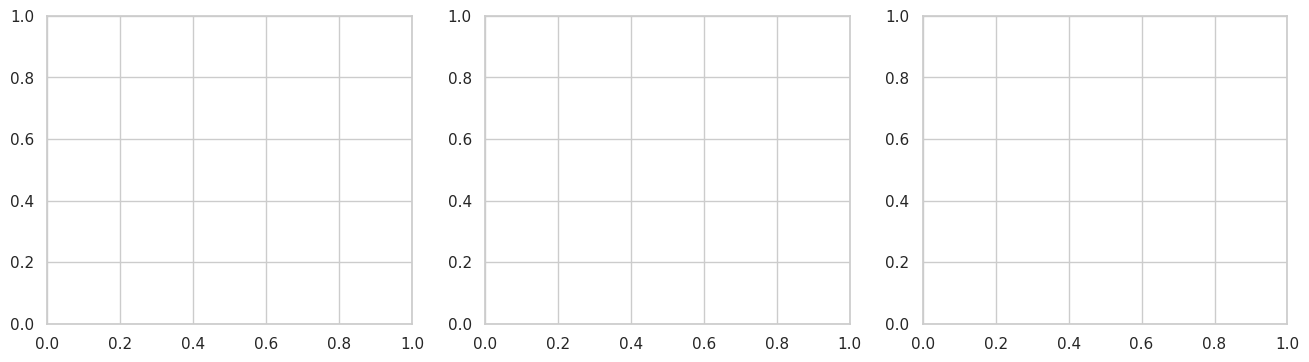

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["charges"], kde=True, ax=axes[0]); axes[0].set_title("Distribuição de charges")
sns.histplot(np.log1p(df["charges"]), kde=True, ax=axes[1]); axes[1].set_title("log(1 + charges)")
sns.histplot(df["bmi"], kde=True, ax=axes[2]); axes[2].set_title("Distribuição do IMC (bmi)")
plt.tight_layout(); plt.show()

print("Assimetria de charges:", round(df["charges"].skew(), 3))
print("Assimetria de log(charges):", round(np.log1p(df["charges"]).skew(), 3))

### 8.2 Variáveis categóricas

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["sex", "smoker", "region"]):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"Frequência de {col}")
plt.tight_layout(); plt.show()

for col in ["smoker", "sex", "region"]:
    print(f"\nCusto médio por {col}:")
    print(df.groupby(col)["charges"].agg(["count", "mean", "median"]).round(2))

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["smoker", "sex", "region"]):
    sns.boxplot(data=df, x=col, y="charges", ax=ax)
    ax.set_title(f"charges por {col}")
plt.tight_layout(); plt.show()

### 8.3 Correlações e 8.4 Heatmap

In [ ]:
df_corr = df.copy()
df_corr["smoker_yes"] = (df_corr["smoker"] == "yes").astype(int)
df_corr["sex_male"] = (df_corr["sex"] == "male").astype(int)

cols_corr = ["age", "bmi", "children", "smoker_yes", "sex_male", "charges"]
corr_all = df_corr[cols_corr].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_all, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlação (inclui smoker e charges)")
plt.show()

print("Correlação de cada variável com charges:")
print(corr_all["charges"].drop("charges").sort_values(ascending=False).round(3))

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=0.6, ax=axes[0])
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=0.6, ax=axes[1])
sns.scatterplot(data=df, x="children", y="charges", hue="smoker", alpha=0.6, ax=axes[2])
axes[0].set_title("Idade × charges"); axes[1].set_title("IMC × charges"); axes[2].set_title("Filhos × charges")
plt.tight_layout(); plt.show()

### 8.5 Outliers

In [ ]:
def outliers_iqr(serie):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)

for col in ["charges", "bmi", "age", "children"]:
    mask = outliers_iqr(df[col])
    print(f"{col}: {mask.sum()} outliers pelo critério do IQR ({mask.mean()*100:.1f}%)")

z = (df["charges"] - df["charges"].mean()) / df["charges"].std()
print(f"\ncharges com |z-score| > 3: {(z.abs() > 3).sum()}")

plt.figure(figsize=(8, 3))
sns.boxplot(x=df["charges"]); plt.title("Boxplot de charges"); plt.show()

**Decisão sobre os outliers:** os valores extremos de `charges` **foram mantidos**. Eles representam casos reais de custo alto (por exemplo, fumantes com IMC elevado) e removê-los faria o modelo ignorar justamente os beneficiários de maior risco para a seguradora.

## 9. Multicolinearidade

In [ ]:
numerical_features = ["age", "bmi", "children"]
corr_features = df[numerical_features].corr()

plt.figure(figsize=(5, 4))
sns.heatmap(corr_features, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação entre variáveis numéricas preditoras")
plt.show()

print("age × bmi:      ", round(corr_features.loc["age", "bmi"], 3))
print("age × children: ", round(corr_features.loc["age", "children"], 3))
print("bmi × children: ", round(corr_features.loc["bmi", "children"], 3))

## 10. Pré-processamento

### 10.1 X / y e 10.2 Train/Test

In [ ]:
X = df.drop("charges", axis=1)
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Treino: {X_train.shape[0]} registros | Teste: {X_test.shape[0]} registros | Variáveis de entrada: {X_train.shape[1]}")

### 10.3 One-Hot Encoding e 10.4 StandardScaler

In [ ]:
numeric_cols = ["age", "bmi", "children"]
categorical_cols = ["sex", "smoker", "region"]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols),
])

# Função de avaliação usada em todo o notebook
def avaliar_modelo(nome, y_true, y_pred):
    return {
        "Modelo": nome,
        "R²": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    }

## 11. Regressão Linear

In [ ]:
linear_model = Pipeline(steps=[("preprocessor", preprocessor), ("model", LinearRegression())])
linear_model.fit(X_train, y_train)
pred_linear = linear_model.predict(X_test)

res_linear = avaliar_modelo("Regressão Linear", y_test, pred_linear)
print({k: (round(v, 4) if not isinstance(v, str) else v) for k, v in res_linear.items()})

## 12. Random Forest

In [ ]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE)),
])
rf_model.fit(X_train, y_train)
pred_rf = rf_model.predict(X_test)

res_rf = avaliar_modelo("Random Forest (inicial)", y_test, pred_rf)
print({k: (round(v, 4) if not isinstance(v, str) else v) for k, v in res_rf.items()})

## 13. SVR

In [ ]:
svr_model = Pipeline(steps=[("preprocessor", preprocessor), ("model", SVR())])
svr_model.fit(X_train, y_train)
pred_svr = svr_model.predict(X_test)

res_svr = avaliar_modelo("SVR (padrão)", y_test, pred_svr)
print({k: (round(v, 4) if not isinstance(v, str) else v) for k, v in res_svr.items()})

In [ ]:
resultados_iniciais = pd.DataFrame([res_linear, res_rf, res_svr]).set_index("Modelo").round(4)
display(resultados_iniciais)

## 14. Cross-Validation

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

modelos_iniciais = {
    "Regressão Linear": linear_model,
    "Random Forest (inicial)": rf_model,
    "SVR (padrão)": svr_model,
}
linhas = []
for nome, modelo in modelos_iniciais.items():
    scores = -cross_val_score(modelo, X_train, y_train, cv=cv,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
    linhas.append({"Modelo": nome, "RMSE médio (CV)": scores.mean(), "Desvio padrão": scores.std()})

display(pd.DataFrame(linhas).set_index("Modelo").round(2))

## 15. GridSearch

In [ ]:
# Random Forest
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE)),
])
rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
}
rf_search = GridSearchCV(rf_pipeline, rf_param_grid, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1)
rf_search.fit(X_train, y_train)

print("Melhores parâmetros do Random Forest:", rf_search.best_params_)
print("RMSE médio na validação cruzada:", round(-rf_search.best_score_, 2))

In [ ]:
# SVR com o alvo padronizado durante o treinamento.
# O TransformedTargetRegressor converte as previsões de volta para a escala original de charges.
svr_pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", SVR())])
svr_modelo_alvo = TransformedTargetRegressor(
    regressor=svr_pipeline,
    transformer=StandardScaler()
)

svr_param_grid = [
    {
        "regressor__model__kernel": ["linear"],
        "regressor__model__C": [0.1, 1, 10, 100],
        "regressor__model__epsilon": [0.05, 0.1, 0.2],
    },
    {
        "regressor__model__kernel": ["rbf"],
        "regressor__model__C": [1, 10, 100, 1000],
        "regressor__model__epsilon": [0.05, 0.1, 0.2],
        "regressor__model__gamma": ["scale", "auto"],
    },
]
svr_search = GridSearchCV(
    svr_modelo_alvo,
    svr_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)
svr_search.fit(X_train, y_train)

print("Melhores parâmetros do SVR:", svr_search.best_params_)
print("RMSE médio na validação cruzada:", round(-svr_search.best_score_, 2))

## 16. Avaliação final dos modelos

In [ ]:
modelos_ajustados = {
    "Regressão Linear": linear_model,
    "Random Forest ajustado": rf_search.best_estimator_,
    "SVR ajustado": svr_search.best_estimator_,
}

preds_teste = {}
resultados_finais = []
for nome, modelo in modelos_ajustados.items():
    preds_teste[nome] = modelo.predict(X_test)
    resultados_finais.append(avaliar_modelo(nome, y_test, preds_teste[nome]))

tabela_final = pd.DataFrame(resultados_finais).set_index("Modelo")
display(tabela_final.round(4))

## 17. Comparação e interpretação dos resultados

In [ ]:
melhor_rmse = tabela_final["RMSE"].idxmin()
melhor_r2 = tabela_final["R²"].idxmax()
melhor_mape = tabela_final["MAPE (%)"].idxmin()

print(f"Melhor R²:   {melhor_r2}")
print(f"Menor RMSE:  {melhor_rmse}")
print(f"Menor MAE:   {tabela_final['MAE'].idxmin()}")
print(f"Menor MAPE:  {melhor_mape}  (o MAPE é sensível a custos baixos; não deve decidir sozinho)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metrica in zip(axes, ["R²", "MAE", "RMSE"]):
    sns.barplot(x=tabela_final.index, y=tabela_final[metrica], ax=ax)
    ax.set_title(metrica); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

## 18. Valores reais versus valores preditos

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
lim = [0, max(y_test.max(), max(p.max() for p in preds_teste.values()))]
for ax, (nome, pred) in zip(axes, preds_teste.items()):
    ax.scatter(y_test, pred, alpha=0.6)
    ax.plot(lim, lim, "r--", label="Previsão perfeita")
    ax.set_title(nome); ax.set_xlabel("Valor real"); ax.set_ylabel("Valor previsto")
    ax.legend()
plt.tight_layout(); plt.show()

## 19. Análise dos resíduos
Resíduo = valor real − valor previsto (positivo = o modelo **subestimou** o custo).

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for j, (nome, pred) in enumerate(preds_teste.items()):
    residuos = y_test - pred
    sns.histplot(residuos, kde=True, ax=axes[0, j]); axes[0, j].set_title(f"Resíduos — {nome}")
    axes[1, j].scatter(pred, residuos, alpha=0.6)
    axes[1, j].axhline(0, color="r", linestyle="--")
    axes[1, j].set_xlabel("Valor previsto"); axes[1, j].set_ylabel("Resíduo")
plt.tight_layout(); plt.show()

linhas = []
for nome, pred in preds_teste.items():
    r = y_test - pred
    linhas.append({"Modelo": nome, "Resíduo médio": r.mean(), "Desvio padrão": r.std(),
                   "Subestimou (%)": (r > 0).mean() * 100})
display(pd.DataFrame(linhas).set_index("Modelo").round(2))

## 20. Overfitting e generalização

In [ ]:
linhas = []
for nome, modelo in modelos_ajustados.items():
    r2_tr = r2_score(y_train, modelo.predict(X_train))
    r2_te = r2_score(y_test, modelo.predict(X_test))
    rmse_cv = -cross_val_score(modelo, X_train, y_train, cv=cv,
                               scoring="neg_root_mean_squared_error", n_jobs=-1).mean()
    linhas.append({"Modelo": nome, "R² treino": r2_tr, "R² teste": r2_te,
                   "Diferença (treino − teste)": r2_tr - r2_te, "RMSE médio CV": rmse_cv})

display(pd.DataFrame(linhas).set_index("Modelo").round(4))

## 21. Interpretabilidade dos modelos

In [ ]:
rf_best = rf_search.best_estimator_
nomes = rf_best.named_steps["preprocessor"].get_feature_names_out()
imp = pd.Series(rf_best.named_steps["model"].feature_importances_, index=nomes).sort_values()

plt.figure(figsize=(8, 5))
imp.plot(kind="barh")
plt.title("Importância das variáveis — Random Forest ajustado")
plt.xlabel("Importância")
plt.tight_layout(); plt.show()

display(imp.sort_values(ascending=False).round(4).to_frame("Importância"))

## 22. Coeficientes da Regressão Linear

In [ ]:
nomes = linear_model.named_steps["preprocessor"].get_feature_names_out()
coefs = pd.Series(linear_model.named_steps["model"].coef_, index=nomes).sort_values()

plt.figure(figsize=(8, 5))
coefs.plot(kind="barh")
plt.title("Coeficientes da Regressão Linear (age, bmi e children padronizados)")
plt.axvline(0, color="k", linewidth=0.8)
plt.tight_layout(); plt.show()

display(coefs.sort_values(ascending=False).round(2).to_frame("Coeficiente"))
print("Intercepto:", round(linear_model.named_steps["model"].intercept_, 2))

## 23. Escolha do melhor algoritmo

In [ ]:
melhor = tabela_final["RMSE"].idxmin()
print(f"Modelo recomendado (menor RMSE no teste): {melhor}")
display(tabela_final.loc[[melhor]].round(4))

## 24. Discussão e veredito final

A escolha do melhor algoritmo deve ser fundamentada principalmente nas métricas calculadas no conjunto de teste, sem considerar apenas o resultado do treinamento. O **RMSE** penaliza mais os erros grandes; o **MAE** representa o erro absoluto médio na unidade original de `charges`; o **R²** indica a proporção da variabilidade explicada pelo modelo; e o **MAPE** expressa o erro percentual médio, mas pode ser sensível quando existem valores-alvo baixos.

Use os resultados das tabelas e dos gráficos acima para responder:
1. Qual modelo apresentou o menor RMSE e como ficou em relação ao MAE e ao R²?
2. A diferença entre as métricas de treino e teste sugere overfitting?
3. Os resíduos parecem distribuídos aleatoriamente em torno de zero ou mostram padrões?
4. O ganho de desempenho justifica a complexidade adicional em comparação com a Regressão Linear?

Não declare que um modelo é superior em todos os aspectos se as métricas divergirem. A recomendação final deve refletir o equilíbrio entre precisão, generalização, custo computacional e interpretabilidade.

In [ ]:
# Síntese automática baseada nas métricas desta execução
modelo_rmse = tabela_final["RMSE"].idxmin()
modelo_mae = tabela_final["MAE"].idxmin()
modelo_r2 = tabela_final["R²"].idxmax()

print("SÍNTESE DOS RESULTADOS")
print(f"Menor RMSE no teste: {modelo_rmse} ({tabela_final.loc[modelo_rmse, 'RMSE']:.2f})")
print(f"Menor MAE no teste: {modelo_mae} ({tabela_final.loc[modelo_mae, 'MAE']:.2f})")
print(f"Maior R² no teste: {modelo_r2} ({tabela_final.loc[modelo_r2, 'R²']:.4f})")
print("\nInterpretação: use estes resultados junto aos gráficos de valores reais versus preditos, resíduos e à comparação treino/teste para escrever o veredito final.")


## 25. Limitações e trabalhos futuros

- A base contém dados observacionais; correlação entre uma característica e `charges` não comprova causalidade.
- Os resultados dependem da amostra, da divisão treino/teste e dos hiperparâmetros testados.
- A métrica MAPE deve ser interpretada com cautela e em conjunto com MAE e RMSE.
- Como próximos passos, pode-se ampliar a busca de hiperparâmetros, testar validação cruzada repetida e avaliar a estabilidade dos resultados.
- As orientações da disciplina mencionam um dashboard com Streamlit. Esse dashboard é uma entrega separada e precisa ser criado e testado caso seja exigido junto ao relatório e ao notebook.


## 26. Referências bibliográficas

- MIRICHoi0218. **Medical Cost Personal Datasets**. Kaggle. Disponível em: https://www.kaggle.com/datasets/mirichoi0218/insurance. Acesso em: 13 out. 2026.
- PEDREGOSA, F. et al. **Scikit-learn: Machine Learning in Python**. *Journal of Machine Learning Research*, v. 12, p. 2825–2830, 2011. Disponível em: https://jmlr.org/papers/v12/pedregosa11a.html.
- THE PANDAS DEVELOPMENT TEAM. **pandas documentation**. Disponível em: https://pandas.pydata.org/docs/.
- HUNTER, J. D. **Matplotlib: A 2D Graphics Environment**. *Computing in Science & Engineering*, v. 9, n. 3, p. 90–95, 2007. DOI: 10.1109/MCSE.2007.55.
- WASKOM, M. L. **seaborn: statistical data visualization**. *Journal of Open Source Software*, v. 6, n. 60, 3021, 2021. DOI: 10.21105/joss.03021.

> Antes de entregar, execute todas as células do início ao fim, confira se não há erros e exporte o relatório em PDF. O notebook e o relatório devem conter resultados provenientes da mesma execução.